# **Classification of Fligth Destinations**

##Goals

### 1. Identify geographical clusters using distance-based methods

The first goal is to determine how European cities naturally group together based solely on their physical proximity. By computing pairwise distances between cities and applying both Agglomerative Clustering and Spectral Clustering, we uncover geographical partitions that serve as a baseline for comparison. These clusters show how cities would group if only distance mattered, helping us later evaluate how much the real flight network diverges from geographical intuition.

### 2. Model Europe as a network of cheap-flight connections to detect communities and hubs

The second goal is to shift from a geographic perspective to a structural one by modeling Europe as a graph where nodes represent cities and edges represent cheap routes (e.g., flights ≤ €100). Using this network, we apply Louvain Community Detection to find regions of Europe that are densely interconnected through affordable travel. Additionally, we compute betweenness centrality to identify budget hubs—cities that act as key bridges between cheap-travel regions. This perspective reveals the hidden topology of the budget airline network, highlighting patterns that geography alone cannot explain.

### 3. Discover deeper structural patterns using Node2Vec embeddings and hybrid clustering

The final goal is to capture subtle relationships that neither geography nor cheap-route structure fully explains. By generating Node2Vec embeddings, we encode each city’s structural role in the network into a compact numerical vector. These embeddings are combined with tabular features (prices, distances, durations, centralities, etc.) and reduced using PCA. Applying K-means to this hybrid representation uncovers latent clusters, revealing deeper, more complex travel structures such as cities with similar cost behavior, connectivity roles, or travel efficiencies. This step identifies hidden patterns beyond simple geography or graph connectivity.



In [2]:
!pip install node2vec


In [23]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import math
from math import radians, cos, sin, asin, sqrt
import operator

# community (Louvain)
try:
    import community.community_louvain as community_louvain
except Exception:
    # fallback message
    raise ImportError("Please install 'python-louvain' (pip install python-louvain) and retry.")

try:
    import geopandas as gpd
except Exception:
    gpd = None
    print("geopandas not available — plotting will still work but without country outlines. Install geopandas for nicer maps.")

import random, warnings
warnings.filterwarnings("ignore")
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

## Loading the Dataset

In [2]:
from google.colab import files
uploaded = files.upload()


Saving vuelos_kayak_clean_final.csv to vuelos_kayak_clean_final.csv


In [3]:
df = pd.read_csv("vuelos_kayak_clean_final.csv", sep=",")
df.head()


,Date,Month,Day_Name,Weekday,Departure_Time,Arrival_Time,Duration_Minutes,Distance_km,precio,Stops_Numeric,Primary_Airline,Is_Mixed_Carrier,Airline_Count,origen_iata,destino_iata,Origin_Country,Dest_Country,Route,Origin_City,Dest_City
0,2025-12-01,12,Monday,0,2025-12-01 04:30:00,2025-12-01 09:00:00,330.0,2004.341329,184.0,1,Air Serbia,False,1.0,OTP,OSL,Romania,Norway,OTP-OSL,Bucharest,Oslo
1,2025-12-01,12,Monday,0,2025-12-01 04:30:00,2025-12-01 09:00:00,330.0,2004.341329,150.0,1,Air Serbia,False,1.0,OTP,OSL,Romania,Norway,OTP-OSL,Bucharest,Oslo
2,2025-12-01,12,Monday,0,2025-12-01 05:00:00,2025-12-02 03:30:00,1290.0,1722.895007,227.0,1,KLM,False,1.0,LIS,ZRH,Portugal,Switzerland,LIS-ZRH,Lisbon,Zurich
3,2025-12-01,12,Monday,0,2025-12-01 05:35:00,2025-12-01 09:50:00,315.0,2004.341329,300.0,1,LOT,False,1.0,OTP,OSL,Romania,Norway,OTP-OSL,Bucharest,Oslo
4,2025-12-01,12,Monday,0,2025-12-01 05:35:00,2025-12-02 03:55:00,1460.0,2975.121245,240.0,1,LOT,False,1.0,OTP,LIS,Romania,Portugal,OTP-LIS,Bucharest,Lisbon


In [4]:
from node2vec import Node2Vec as Node2VecLib

## 1. **Identify geographical clusters using distance-based methods**

First, we classify the cities using a distance-based approach. Distances between cities are computed with the Haversine formula using their geographic coordinates. We then apply both Spectral Clustering and Agglomerative Clustering to group the cities according to their spatial proximity, providing a geographical baseline for comparison with later network-based methods.

In [10]:
# Coordinates (lat, lon) for easier plotting
city_coords = {
    "Madrid": (40.4168, -3.7038),"London": (51.5074, -0.1278),"Paris": (48.8566, 2.3522),"Berlin": (52.5200, 13.4050),"Rome": (41.9028, 12.4964),
    "Bucharest": (44.4268, 26.1025),"Vienna": (48.2082, 16.3738), "Amsterdam": (52.3676, 4.9041),"Copenhagen": (55.6761, 12.5683),
    "Stockholm": (59.3293, 18.0686),"Oslo": (59.9139, 10.7522), "Helsinki": (60.1699, 24.9384),"Lisbon": (38.7223, -9.1393),"Istanbul": (41.0082, 28.9784),
    "Zurich": (47.3769, 8.5417),"Brussels": (50.8503, 4.3517),"Dublin": (53.3498, -6.2603),"Prague": (50.0755, 14.4378),"Budapest": (47.4979, 19.0402),
    "Athens": (37.9838, 23.7275),"Milan": (45.4642, 9.1900)
}

# ---------- prepare arrays ----------
cities = list(city_coords.keys())           # assume city_coords exists
n = len(cities)
coords = np.array([city_coords[c] for c in cities])   # shape (n,2) as (lat, lon)

# Distance matrix (km)
D = np.zeros((n, n))
for i in range(n):
    lat1, lon1 = coords[i]
    for j in range(i+1, n):
        lat2, lon2 = coords[j]
        d = df[((df["Origin_City"] == cities[i]) & (df["Dest_City"] == cities[j]) | (df["Origin_City"] == cities[i]) & (df["Dest_City"] == cities[j]))]["Distance_km"].unique()
        D[i, j] = d
        D[j, i] = d


Now we perform hierarchical clustering using the distance matrix as input. The objective is to group cities into clusters purely based on how far they are from each other. Using **agglomerative clustering** allows the model to detect natural geographical partitions and compare them later with graph-derived communities and hybrid embeddings.

In [14]:

# ----------------------------
# OPTION A: Agglomerative (precomputed distances)
# ----------------------------
from sklearn.cluster import AgglomerativeClustering

k = 5 # desired clusters
agg = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
labels_agg = agg.fit_predict(D)   # pass distance matrix directly

# Map city -> label
agg_clusters = {i: [] for i in range(k)}
for i, lab in enumerate(labels_agg):
    agg_clusters[lab].append(cities[i])

print("Agglomerative clusters (by distance):")
for lab, members in agg_clusters.items():
    print(lab, members)


Agglomerative clusters (by distance):
0 ['Berlin', 'Rome', 'Vienna', 'Zurich', 'Prague', 'Budapest', 'Milan']
1 ['London', 'Paris', 'Amsterdam', 'Brussels', 'Dublin']
2 ['Bucharest', 'Istanbul', 'Athens']
3 ['Madrid', 'Lisbon']
4 ['Copenhagen', 'Stockholm', 'Oslo', 'Helsinki']


Then we are using **Spectral Clustering**. Distances are transformed into affinities using an RBF (Gaussian) kernel, and spectral clustering is applied. Spectral methods capture non-linear relationships between cities by analyzing the eigenstructure of the similarity graph. Applying this method helps identify whether distance-based proximity can produce smoother, more balanced partitions compared to hierarchical techniques. It also provides a sanity check, since both methods should yield similar clusters if geography strongly governs flight patterns.

In [16]:
# ----------------------------
# OPTION B: Spectral Clustering (from affinity)
# ----------------------------
from sklearn.cluster import SpectralClustering

# Convert distances -> affinity (RBF kernel)
# choose sigma as median distance
sigma = np.median(D[D>0])
if sigma == 0 or np.isnan(sigma):
    sigma = 1.0
A = np.exp(-D / sigma)   # affinity matrix, shape (n,n)

k = 5
spec = SpectralClustering(n_clusters=k, affinity='precomputed', random_state=42)
labels_spec = spec.fit_predict(A)

spec_clusters = {i: [] for i in range(k)}
for i, lab in enumerate(labels_spec):
    spec_clusters[lab].append(cities[i])

print("\nSpectral clusters (RBF affinity):")
for lab, members in spec_clusters.items():
    print(lab, members)


Spectral clusters (RBF affinity):
0 ['London', 'Paris', 'Amsterdam', 'Brussels', 'Dublin']
1 ['Copenhagen', 'Stockholm', 'Oslo', 'Helsinki']
2 ['Madrid', 'Lisbon']
3 ['Bucharest', 'Istanbul', 'Athens']
4 ['Berlin', 'Rome', 'Vienna', 'Zurich', 'Prague', 'Budapest', 'Milan']


Both clustering methods produce identical geographical groupings, confirming that the structure is strongly driven by physical proximity. The resulting clusters reflect well-defined European regions:

Cluster 1 – **Iberian Peninsula**: Madrid, Lisbon

Cluster 2 – **Northern Europe**: Copenhagen, Stockholm, Oslo, Helsinki

Cluster 3 – **Eastern Europe**: Bucharest, Athens, Budapest

Cluster 4 – **Central Europe**: Berlin, Rome, Vienna, Zurich, Prague, Milan

Cluster 5 – **Western Europe**: London, Paris, Amsterdam, Brussels, Dublin

We are saving the results into a dictionary for future usage:

In [18]:
# Map each spectral cluster label to its real region name
cluster_names = {
    2: "iberian_peninsula",
    1: "northern_europe",
    3: "eastern_europe",
    4: "central_europe",
    0: "western_europe"
}

# Build results dictionary with meaningful names
results = {
    cluster_names[lab]: members
    for lab, members in spec_clusters.items()
}



{'western_europe': ['London', 'Paris', 'Amsterdam', 'Brussels', 'Dublin'], 'northern_europe': ['Copenhagen', 'Stockholm', 'Oslo', 'Helsinki'], 'iberian_peninsula': ['Madrid', 'Lisbon'], 'eastern_europe': ['Bucharest', 'Istanbul', 'Athens'], 'central_europe': ['Berlin', 'Rome', 'Vienna', 'Zurich', 'Prague', 'Budapest', 'Milan']}


## 2. **Model Europe as a network of cheap-flight connections to detect communities and hubs**
Model Europe as a **connected web** where:
- **Nodes** = Cities  
- **Edges** = At least one flight exists with price ≤ a defined budget threshold (e.g., €100)

### ** We will compute:**
1. **Louvain Community Detection**  
   Groups cities into "zones" based on how cheaply they connect to each other.  
   → Output: colored clusters on the map.

2. **Betweenness Centrality**  
   Identifies “budget hubs” — cities acting as bridges between regions.  
   → Output: larger node sizes for more central cities.


---

### Identifying Cheap Flight Connections and Building the Graph

This section filters flight routes based on a price threshold to identify which city pairs are connected by cheap flights. These cheap connections become edges in a graph where each city is a node.

The resulting graph highlights which cities are tightly connected through budget routes and which remain isolated or expensive, setting the foundation for network community detection and structural embeddings.


In [19]:
CHEAP_THRESHOLD = 100
cheap_edges = set()
edge_prices = {}  # (a,b) -> min price

for _, row in df.iterrows():
    o = row["Origin_City"]
    d = row["Dest_City"]
    p = row["precio"]
    if pd.isna(p):
        continue
    if p <= CHEAP_THRESHOLD:
        a, b = sorted([o, d])
        cheap_edges.add((a, b))
        edge_prices[(a, b)] = min(edge_prices.get((a, b), np.inf), p)

print("Cheap edges found:", len(cheap_edges))


Cheap edges found: 209


In [21]:
CHEAP_THRESHOLD = 100.0
G = nx.Graph()
nodes_in_data = sorted(set(list(df["Origin_City"].unique()) + list(df["Dest_City"].unique())))
for city in nodes_in_data:
    G.add_node(city, pos=(city_coords[city][1], city_coords[city][0]))

for (a, b) in cheap_edges:
    #weight is the min. price between a and b
    w = edge_prices.get((a, b), CHEAP_THRESHOLD)
    G.add_edge(a, b, weight=w)

print(f"Graph: {G.number_of_nodes()} cities, {G.number_of_edges()} cheap edges")


Graph: 21 cities, 209 cheap edges


### **Louvain Community Detection**

We compute:
- A dictionary `partition` mapping each city to its community/zone  
- The number of detected communities


The purpose is to model Europe not as a simple geographical space, but as a network shaped by **price-efficient travel**.

The resulting graph highlights which cities are tightly connected through budget routes and which remain isolated or expensive.

In [34]:
partition = community_louvain.best_partition(G, weight='weight')
communities = sorted(set(partition.values()))
print("Detected communities:", len(communities))

def louvain_to_communities(partition):
    #Converts Louvain output to node groups format
    comm_map = {}
    for node, cid in partition.items():
        comm_map.setdefault(cid, set()).add(node)
    communities = list(comm_map.values())
    communities.sort(key=lambda s: (-len(s), sorted(s)))
    return communities
louvain_comms = louvain_to_communities(partition)
for i,c in enumerate(sorted(louvain_comms, key=lambda s: -len(s)), 1):
    print(f"   C{i} (size={len(c)}): {sorted(c)}")

Detected communities: 2
   C1 (size=11): ['Amsterdam', 'Athens', 'Brussels', 'Budapest', 'Copenhagen', 'Lisbon', 'Madrid', 'Milan', 'Prague', 'Stockholm', 'Zurich']
   C2 (size=10): ['Berlin', 'Bucharest', 'Dublin', 'Helsinki', 'Istanbul', 'London', 'Oslo', 'Paris', 'Rome', 'Vienna']


#### Interpretation of Louvain Communities

These communities represent groups of cities that are more densely and cheaply interconnected with each other than with the rest of the network. Instead of reflecting geographical proximity, they reveal the underlying structure of Europe’s budget flight system.

####  Community 1  
Cities such as **Madrid**, **Lisbon**, **Amsterdam**, **Milan**, and **Stockholm** form a cohesive zone of inexpensive travel linking parts of Western and Southern Europe.

#### Community 2  
Cities including **London**, **Paris**, **Rome**, **Berlin**, and **Istanbul** make up a distinct sub-network where cheap connections concentrate around Europe’s major metropolitan hubs.

####  Overall Interpretation  
These communities illustrate how low-cost airline routes naturally organize European cities into **“travel zones”** shaped by pricing dynamics, airline competition, and route density—rather than by physical distance alone.


### **Betweenness Centrality (Budget Hubs)**

Betweenness centrality measures how often a node lies on shortest paths  
between other nodes.

Interpretation:
- Higher value → city acts as a **bridge** between zones  
- Identifies the most strategic “budget hubs” for cheap travel across Europe


In [35]:
bet_cent = nx.betweenness_centrality(G, normalized=True, weight='weight')
nx.set_node_attributes(G, bet_cent, "betweenness")

top_hubs = sorted(bet_cent.items(), key=lambda x: x[1], reverse=True)[:10]

print("Top Budget Hubs:")
for city, val in top_hubs:
    print(f"  {city}: {val:.4f}")


Top Budget Hubs:
  Milan: 0.0833
  Brussels: 0.0675
  Stockholm: 0.0553
  London: 0.0491
  Rome: 0.0421
  Budapest: 0.0342
  Paris: 0.0289
  Vienna: 0.0158
  Dublin: 0.0105
  Madrid: 0.0105


In [36]:
communities_and_hubs = {
    "louvain_community_1": louvain_comms[0],
    "louvain_community_2": louvain_comms[1],
    "budget_hubs": [city for city, _ in top_hubs]

}
results.update(communities_and_hubs)

## 3. **Discover deeper structural patterns using Node2Vec embeddings and hybrid clustering**

The final goal is to capture subtle relationships that neither geography nor cheap-route structure fully explains.

By generating Node2Vec embeddings, we encode each city’s structural role in the network into a compact numerical vector. These embeddings are combined with tabular features (prices, distances, durations, centralities, etc.) and reduced using PCA.

Applying K-means to this hybrid representation uncovers latent clusters, revealing deeper, more complex travel structures such as cities with similar cost behavior, connectivity roles, or travel efficiencies. This step identifies hidden patterns beyond simple geography or graph connectivity.

### Route-Level Aggregation and Feature Engineering

In this part, the dataset is aggregated at the route level to compute meaningful features such as mean/median price, distance, duration, stops, and proportion of cheap flights. Additional attributes such as price-per-kilometer, dominant airline, and temporal patterns are also extracted.

This aggregation transforms raw flight entries into structured features that describe each connection between cities. These metrics later feed into the per-city feature construction and ultimately into the hybrid clustering model.

In [38]:
CHEAP_THRESHOLD = 100.0

# Work on a copy
df_proc = df.copy()

# Normalize column names (strip spaces)
df_proc.columns = [c.strip() for c in df_proc.columns]

# Ensure necessary columns exist and correct dtypes
# Price (from 'precio')
df_proc['Price'] = pd.to_numeric(df_proc['precio'], errors='coerce')


# Duration in minutes -> convert to hours for convenience
df_proc['Duration_Minutes'] = pd.to_numeric(df_proc['Duration_Minutes'], errors='coerce')
df_proc['Duration_hours'] = df_proc['Duration_Minutes'] / 60.0


# Distance_km already present: ensure numeric
df_proc['Distance_km'] = pd.to_numeric(df_proc['Distance_km'], errors='coerce')


# Stops numeric
df_proc['Stops_num'] = pd.to_numeric(df_proc['Stops_Numeric'], errors='coerce')


# Cheap flag per flight
df_proc['is_cheap'] = df_proc['Price'] <= CHEAP_THRESHOLD

# --- Aggregation per (Origin_City, Dest_City) ---
group_cols = ['Origin_City', 'Dest_City']  # route-level aggregation

agg_dict = {
    'Price': ['mean', 'median', 'min', 'count'],
    'Distance_km': ['mean', 'median'],
    'Duration_hours': ['mean', 'median'],
    'Stops_num': ['mean', 'median'],
    'is_cheap': ['mean']  # proportion of cheap flights
}

# keep only existing keys
agg_dict = {k: v for k, v in agg_dict.items() if k in df_proc.columns}

df_routes = df_proc.groupby(group_cols).agg(agg_dict)

# flatten multiindex columns
df_routes.columns = ['_'.join(col).strip() for col in df_routes.columns.to_flat_index()]
df_routes = df_routes.reset_index()

# rename columns to clearer names
rename_map = {
    'Price_mean': 'Price_mean',
    'Price_median': 'Price_median',
    'Price_min': 'Price_min',
    'Price_count': 'Flights_count',
    'Distance_km_mean': 'Distance_km_mean',
    'Distance_km_median': 'Distance_km_median',
    'Duration_hours_mean': 'Duration_hours_mean',
    'Duration_hours_median': 'Duration_hours_median',
    'Stops_num_mean': 'Stops_mean',
    'Stops_num_median': 'Stops_median',
    'is_cheap_mean': 'Pct_cheap_flights'
}
df_routes.rename(columns={k: v for k, v in rename_map.items() if k in df_routes.columns}, inplace=True)

# --- Price per km ---
if 'Price_mean' in df_routes.columns and 'Distance_km_mean' in df_routes.columns:
    df_routes['Price_per_km'] = df_routes['Price_mean'] / df_routes['Distance_km_mean'].replace({0: np.nan})

# --- Top airline (dominant carrier) per route ---
if 'Primary_Airline' in df_proc.columns:
    top_airline = (df_proc.groupby(group_cols)['Primary_Airline']
                          .agg(lambda s: s.mode().iat[0] if not s.mode().empty else np.nan)
                          .reset_index()
                          .rename(columns={'Primary_Airline': 'Top_airline'}))
    df_routes = df_routes.merge(top_airline, on=group_cols, how='left')

# --- Add sample temporal info: earliest/latest date on route, month distribution ---
if 'Date' in df_proc.columns:
    df_dates = df_proc.groupby(group_cols).agg(
        first_date = ('Date', lambda s: pd.to_datetime(s, errors='coerce').min()),
        last_date  = ('Date', lambda s: pd.to_datetime(s, errors='coerce').max())
    ).reset_index()
    df_routes = df_routes.merge(df_dates, on=group_cols, how='left')

# --- Round numeric columns to 3 decimals where appropriate ---
for c in df_routes.select_dtypes(include=[np.number]).columns:
    df_routes[c] = df_routes[c].round(3)

# --- Reorder columns for readability ---
cols_order = ['Origin_City', 'Dest_City'] + [c for c in df_routes.columns if c not in ('Origin_City','Dest_City')]
df_routes = df_routes[cols_order]

# --- Save & display ---
df_routes.to_csv("df_routes_aggregated.csv", index=False)
print("df_routes created:", df_routes.shape)
display(df_routes.head(5))


df_routes created: (211, 17)


,Origin_City,Dest_City,Price_mean,Price_median,Price_min,Flights_count,Distance_km_mean,Distance_km_median,Duration_hours_mean,Duration_hours_median,Stops_mean,Stops_median,Pct_cheap_flights,Price_per_km,Top_airline,first_date,last_date
0,Amsterdam,Athens,197.459,184.0,97.0,303,2163.085,2163.085,14.572,17.167,0.558,1.0,0.010,0.091,KLM,2025-12-17,2026-08-17
1,Amsterdam,Brussels,223.452,201.5,12.0,312,172.973,172.973,12.498,15.950,0.657,1.0,0.016,1.292,KLM,2025-12-06,2026-08-22
2,Amsterdam,Budapest,181.482,173.0,82.0,365,1144.835,1144.835,14.000,16.000,0.710,1.0,0.008,0.159,KLM,2025-12-16,2026-08-27
3,Amsterdam,Copenhagen,155.615,149.0,47.0,327,620.718,620.718,9.748,15.167,0.187,0.0,0.135,0.251,KLM,2025-12-02,2026-08-26
4,Amsterdam,Dublin,134.492,121.5,31.0,364,756.663,756.663,11.528,15.667,0.179,0.0,0.231,0.178,KLM,2025-12-05,2026-08-22


### Constructing a Graph from Aggregated Routes

In [39]:
G = nx.Graph()

for _, row in df_routes.iterrows():
    origin = row["Origin_City"]
    dest = row["Dest_City"]
    price = row["Price_min"]

    G.add_edge(origin, dest, weight=price)

edge_prices = {}

for _, row in df_routes.iterrows():
    a, b = sorted([row["Origin_City"], row["Dest_City"]])
    edge_prices[(a, b)] = row["Price_min"]    # the price of each edge is the min price between those nodes


### Creating Per-City Numerical Features

For each city (or node), diverse features are computed: average price, minimum price, proportion of cheap edges, degree, betweenness, closeness, average distance of its routes, average duration, average stops, and geographical coordinates.

These variables capture a city’s economic, structural, and geographical behavior within the flight network. This feature table forms the tabular component of the hybrid embedding used for clustering.

In [40]:
cities = list(G.nodes())
features = []

# Precompute centralities once
betweenness_dict = nx.betweenness_centrality(G, weight="weight")
closeness_dict = nx.closeness_centrality(G)
CHEAP_THRESHOLD = 50 #In this case the threshold is 50 to find really cheap cities
for city in cities:
    # --- Prices from graph edges ---
    prices = []
    cheap_count = 0

    for nbr in G.neighbors(city):
        a, b = tuple(sorted([city, nbr]))
        p = edge_prices.get((a, b), None)
        if p is not None:
            prices.append(p)
            if p <= CHEAP_THRESHOLD:
                cheap_count += 1

    avg_price = np.mean(prices) if prices else np.nan
    min_price = np.min(prices) if prices else np.nan
    median_price = np.median(prices) if prices else np.nan
    pct_cheap_edges = cheap_count / len(prices) if prices else 0.0

    # --- Connectivity ---
    degree = G.degree(city)
    betweenness = betweenness_dict.get(city, 0)
    closeness = closeness_dict.get(city, 0)

    # --- Route data from df_routes (BOTH origin and dest) ---
    df_city = df_routes[(df_routes["Origin_City"] == city) | (df_routes["Dest_City"] == city)]

    avg_distance = df_city["Distance_km_mean"].mean() if "Distance_km_mean" in df_city else np.nan
    avg_duration = df_city["Duration_hours_mean"].mean() if "Duration_hours_mean" in df_city else np.nan
    avg_stops = df_city["Stops_mean"].mean() if "Stops_mean" in df_city else np.nan

    # --- Coordinates ---
    lat = city_coords[city][0]
    lon = city_coords[city][1]

    # --- Save feature vector ---
    features.append({
        "city": city,
        "avg_price": avg_price,
        "min_price": min_price,
        "median_price": median_price,
        "pct_cheap_edges": pct_cheap_edges,

        "degree": degree,
        "betweenness": betweenness,
        "closeness": closeness,

        "avg_distance_km": avg_distance,
        "avg_duration_hours": avg_duration,
        "avg_stops": avg_stops,

        "latitude": lat,
        "longitude": lon
    })

df_features = pd.DataFrame(features).set_index("city")
df_features


,avg_price,min_price,median_price,pct_cheap_edges,degree,betweenness,closeness,avg_distance_km,avg_duration_hours,avg_stops,latitude,longitude
city,,,,,,,,,,,,
Amsterdam,60.15,12.0,58.0,0.45,20,0.000000,1.0,1074.465700,11.627150,0.384300,52.3676,4.9041
Athens,45.20,18.0,42.0,0.65,20,0.000000,1.0,1880.621500,13.049150,0.554850,37.9838,23.7275
Brussels,29.00,8.0,24.5,0.95,20,0.067544,1.0,1057.835100,12.383900,0.540900,50.8503,4.3517
Budapest,30.75,9.0,27.5,0.90,20,0.034211,1.0,1157.119900,13.369350,0.753600,47.4979,19.0402
Copenhagen,34.30,16.0,30.5,0.90,20,0.000000,1.0,1165.268850,12.136300,0.501800,55.6761,12.5683
Dublin,31.40,16.0,27.5,0.90,20,0.010526,1.0,1563.606250,13.429550,0.678400,53.3498,-6.2603
Helsinki,55.70,19.0,58.0,0.45,20,0.000000,1.0,1743.212350,13.232050,0.727250,60.1699,24.9384
Istanbul,44.20,24.0,42.0,0.75,20,0.000000,1.0,1914.778350,12.895500,0.439200,41.0082,28.9784
Lisbon,42.90,10.0,41.0,0.65,20,0.000000,1.0,2198.912300,12.621050,0.580400,38.7223,-9.1393


### Node2Vec embeddings

Node2Vec is applied to the weighted graph to learn a vector representation for each city based on its structural role in the network. These embeddings encode patterns such as neighborhood similarity, community membership, and connectivity importance.

They are essential because they provide a dense numerical representation of graph structure that can be mixed with traditional features for a richer clustering model.

In [41]:

# --- parameters ---
EMB_SIZE = 64 #64 size vector
WALKS_PER_NODE = 10
WALK_LENGTH = 40
WINDOW = 5
MIN_COUNT = 0
RANDOM_STATE = 42
random.seed(RANDOM_STATE)

# Using node2vec library
node2vec = Node2VecLib(G, dimensions=EMB_SIZE, walk_length=WALK_LENGTH,num_walks=WALKS_PER_NODE, workers=1, seed=RANDOM_STATE)
model_n2v = node2vec.fit(window=WINDOW, min_count=MIN_COUNT, batch_words=4, vector_size=EMB_SIZE, seed=RANDOM_STATE)
emb_dict = {str(node): model_n2v.wv.get_vector(str(node)) for node in G.nodes()}

# Convert to DataFrame
emb_df = pd.DataFrame.from_dict(emb_dict, orient='index')
emb_df.index.name = 'city'
emb_df.columns = [f"n2v_{i}" for i in range(emb_df.shape[1])]

# Align types (city names to strings)
emb_df.index = emb_df.index.astype(str)

emb_df.head()

Computing transition probabilities:   0%|          | 0/21 [00:00<?, ?it/s]

Generating walks (CPU: 1): 100%|██████████| 10/10 [00:00<00:00, 231.64it/s]


,n2v_0,n2v_1,n2v_2,n2v_3,n2v_4,n2v_5,n2v_6,n2v_7,n2v_8,n2v_9,...,n2v_54,n2v_55,n2v_56,n2v_57,n2v_58,n2v_59,n2v_60,n2v_61,n2v_62,n2v_63
city,,,,,,,,,,,,,,,,,,,,,
Amsterdam,-0.010135,-0.087312,0.302900,0.074762,0.020014,-0.256321,-0.038104,-0.089414,-0.011440,-0.016009,...,-0.097741,-0.088402,0.053190,-0.063622,-0.070986,0.016569,-0.109158,0.067905,0.016627,0.199544
Athens,-0.003984,-0.075846,0.297773,0.082169,0.021550,-0.253573,-0.037512,-0.085622,-0.007934,-0.021897,...,-0.091740,-0.073630,0.054144,-0.069227,-0.086718,0.012550,-0.127646,0.059170,0.033438,0.196125
Brussels,0.002244,-0.095721,0.278837,0.071508,0.040036,-0.263104,-0.050033,-0.089815,-0.003707,-0.012304,...,-0.091906,-0.068537,0.067447,-0.053121,-0.061118,0.019675,-0.129908,0.079912,0.038021,0.208392
Budapest,-0.017004,-0.085335,0.305927,0.070699,0.050021,-0.257861,-0.044787,-0.085207,0.001411,-0.019857,...,-0.089083,-0.067855,0.051671,-0.068533,-0.086681,0.006286,-0.133473,0.054824,0.038663,0.204406
Copenhagen,-0.008338,-0.094130,0.271827,0.083826,0.021672,-0.269762,-0.054325,-0.067387,-0.013710,0.002117,...,-0.102659,-0.082700,0.057300,-0.068335,-0.065032,0.020361,-0.123069,0.071596,0.042183,0.185979


### Combining Tabular Features and Node2Vec Embeddings, then PCA reduction

Node2Vec embeddings and tabular features are concatenated to form hybrid vectors that describe each city both structurally (graph-based) and descriptively (data-based).

Before concatenation, missing values are imputed and features are standardized to ensure consistent scaling. This hybrid feature space provides a high-dimensional representation that integrates economic, geographical, and structural aspects of each city.

PCA is applied to the hybrid feature space to reduce dimensionality while retaining most of the variance. This step simplifies the representation, removes noise, and makes the clustering process more stable and interpretable. The PCA components become the final input for the clustering algorithm and help visualize the distribution of cities in a reduced space.

In [42]:
# PARAMETERS
N_PCA_COMPONENTS = 20
RANDOM_STATE = 42

# ------------------------------------
# 1) Select numeric tabular features
# ------------------------------------
numeric_cols = df_features.select_dtypes(include=[np.number]).columns.tolist()

# Optionally remove latitude/longitude if you don't want geographical dominance
drop_cols = ["latitude", "longitude"]
features_cols = [c for c in numeric_cols if c not in drop_cols]

print("Using tabular features:", features_cols)

X_tab = df_features[features_cols].values.astype(float)
X_emb = emb_df.values.astype(float)

# ------------------------------------
# 2) Imputation
# ------------------------------------
imp_tab = SimpleImputer(strategy="median")
X_tab_imp = imp_tab.fit_transform(X_tab)

imp_emb = SimpleImputer(strategy="mean")
X_emb_imp = imp_emb.fit_transform(X_emb)

# ------------------------------------
# 3) Scaling
# ------------------------------------
scaler_tab = StandardScaler()
X_tab_scaled = scaler_tab.fit_transform(X_tab_imp)

scaler_emb = StandardScaler()
X_emb_scaled = scaler_emb.fit_transform(X_emb_imp)

# ------------------------------------
# 4) Concatenate hybrid vector
# ------------------------------------
X_hybrid = np.hstack([X_emb_scaled, X_tab_scaled])
print("Hybrid embedding shape:", X_hybrid.shape)

# ------------------------------------
# 5) PCA reduction
# ------------------------------------
n_components = min(N_PCA_COMPONENTS, X_hybrid.shape[1])
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_hybrid)

print(f"PCA components: {n_components}")
print(f"Cumulative explained variance: {np.sum(pca.explained_variance_ratio_):.3f}")

# ------------------------------------
# 6) Save PCA components back to df_features
# ------------------------------------
pca_cols = [f"hybrid_pca_{i}" for i in range(X_pca.shape[1])]
for i, col in enumerate(pca_cols):
    df_features[col] = X_pca[:, i]


print("Hybrid PCA-ready dataset created and saved.")
display(df_features[pca_cols].head())

Using tabular features: ['avg_price', 'min_price', 'median_price', 'pct_cheap_edges', 'degree', 'betweenness', 'closeness', 'avg_distance_km', 'avg_duration_hours', 'avg_stops']
Hybrid embedding shape: (21, 74)
PCA components: 20
Cumulative explained variance: 1.000
Hybrid PCA-ready dataset created and saved.


,hybrid_pca_0,hybrid_pca_1,hybrid_pca_2,hybrid_pca_3,hybrid_pca_4,hybrid_pca_5,hybrid_pca_6,hybrid_pca_7,hybrid_pca_8,hybrid_pca_9,hybrid_pca_10,hybrid_pca_11,hybrid_pca_12,hybrid_pca_13,hybrid_pca_14,hybrid_pca_15,hybrid_pca_16,hybrid_pca_17,hybrid_pca_18,hybrid_pca_19
city,,,,,,,,,,,,,,,,,,,,
Amsterdam,2.652181,1.404618,4.529953,1.087666,0.510289,1.656583,-1.981585,1.562643,2.392653,1.062093,1.091742,-0.551241,-0.798190,0.293257,-0.664128,-0.878136,-0.970582,-3.794701,-0.015955,0.516709
Athens,0.913057,-0.661772,-0.607554,-0.414887,-0.454882,4.275706,-0.406609,-1.412390,-4.100541,1.311769,1.812490,-0.566202,-2.348145,0.454585,-1.015449,-1.534165,-1.990645,1.297006,-0.804114,-0.798010
Brussels,-2.999867,-3.242843,-2.164086,-1.712982,-3.472436,2.623453,2.090647,1.992391,2.441140,0.421388,-0.117263,-0.931404,-1.356919,-1.618603,-0.361740,-0.295701,1.163461,-0.372655,2.251781,-1.214437
Budapest,0.588393,0.345132,1.268823,-2.260552,-0.984886,-1.629849,3.407066,1.474045,-0.592899,-1.735516,-0.408269,-2.093643,-0.339168,1.063538,-2.457184,-0.661817,2.112970,-0.263630,-2.664173,0.049016
Copenhagen,-1.787129,-0.221814,-4.301833,-0.407870,0.965831,0.542670,-1.850500,-1.256316,0.666558,0.087512,0.521563,-1.746901,0.392207,0.666557,4.210239,-1.832284,1.499431,-0.874353,-1.409947,0.054596


###  K-Means Clustering on Hybrid PCA

K-means is applied to the PCA-reduced hybrid embeddings to classify cities into meaningful groups. This clustering integrates all previously computed information: structural roles, economic patterns, cheap-route connectivity, and geographical behaviors.

The result is a set of clusters that reflect the real dynamics of the European flight network.

Cluster sizes (k=3):
0     3
1    13
2     5

Cluster centroids (means of selected features):


,degree,betweenness
hybrid_cluster_kmeans,,
0,20.0,0.018
1,20.0,0.024
2,20.0,0.007


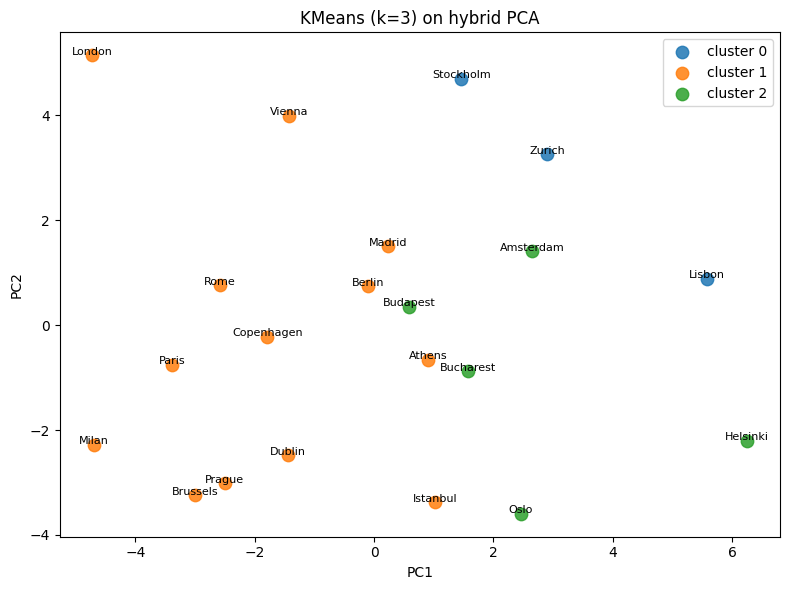

In [44]:

K = 3

# 1) Prepare data for clustering: prefer X_pca, else hybrid_pca_* cols
if 'X_pca' in globals():
    X = X_pca
else:
    pca_cols = [c for c in df_features.columns if c.startswith("hybrid_pca_")]
    if len(pca_cols) == 0:
        raise RuntimeError("No X_pca or hybrid_pca_* found. Run the PCA step first.")
    X = df_features[pca_cols].values.astype(float)

# 2) Fit KMeans with k=3
km = KMeans(n_clusters=K, random_state=42, n_init=50)
labels = km.fit_predict(X)
df_features['hybrid_cluster_kmeans'] = labels

# 3) Print cluster sizes
sizes = pd.Series(labels).value_counts().sort_index()
print("Cluster sizes (k=3):")
print(sizes.to_string())

# 4) Quick cluster summary: mean of a few informative features if present
preferred = [c for c in ['price_mean_in','price_mean_out','price_median_incident','cheap_ratio','degree','betweenness','pagerank','avg_neighbor_distance_km'] if c in df_features.columns]
if not preferred:
    # fallback: numeric columns (limited)
    preferred = list(df_features.select_dtypes(include=[np.number]).columns[:8])

print("\nCluster centroids (means of selected features):")
display(df_features.groupby('hybrid_cluster_kmeans')[preferred].mean().round(3))

# 5) 2D scatter using first two PCA components (if available)
if X.shape[1] >= 2:
    x = X[:,0]
    y = X[:,1]
    plt.figure(figsize=(8,6))
    for lbl in sorted(np.unique(labels)):
        mask = labels == lbl
        plt.scatter(x[mask], y[mask], s=80, alpha=0.85, label=f"cluster {lbl}")
    # annotate points with city names (optional — will clutter if many)
    for i, city in enumerate(df_features.index):
        plt.text(x[i], y[i]+0.01, city, fontsize=8, ha='center')
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("KMeans (k=3) on hybrid PCA")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough PCA components to plot 2D scatter.")


In [ ]:
# Print cities inside each cluster (simple + clean)
clusters = sorted(df_features["hybrid_cluster_kmeans"].unique())

for c in clusters:
    cities = df_features[df_features["hybrid_cluster_kmeans"] == c].index.tolist()
    print(f"\nCluster {c} ({len(cities)} cities):")
    for city in cities:
        print(" -", city)



Cluster 0 (3 cities):
 - Lisbon
 - Stockholm
 - Zurich

Cluster 1 (8 cities):
 - Amsterdam
 - Athens
 - Budapest
 - Helsinki
 - Oslo
 - Bucharest
 - Vienna
 - Madrid

Cluster 2 (10 cities):
 - Brussels
 - Copenhagen
 - Dublin
 - Istanbul
 - Milan
 - Prague
 - Berlin
 - Rome
 - London
 - Paris


##  Cluster Interpretations

---

##  Cluster 0 — **High-cost Peripheral Outliers**
**Cities:** Lisbon, Stockholm, Zurich  
**Size:** 3  

This cluster groups cities that behave as expensive, low-connectivity outliers within the European flight network.

### 1. **Higher prices and fewer cheap routes**
These cities typically show:
- Higher median flight prices  
- A lower cheap-ratio (fewer low-cost connections)  
- Less presence of ultra-low-cost carriers  

Stockholm and Zurich are known for consistently high fares, while Lisbon tends to be less competitive in pan-European low-cost markets.

### 2. **Lower structural centrality**
They are not key connectors in the network:
- Lower **degree** (fewer direct links)  
- Low **betweenness** → rarely serve as bridges between regions  
- Overall low structural centrality  

### 3. **Geographical peripherality**
These cities are geographically distant from many others, which increases average route distances, reduces competition, and pushes prices upward.

** Cluster meaning:**  
A group of *peripheral, high-cost nodes*: attractive destinations but not structurally important nor cost-efficient for multi-city routing.

---

##  Cluster 1 — **Balanced Mid-range Connectors**
**Cities:** Amsterdam, Athens, Budapest, Helsinki, Oslo, Bucharest, Vienna, Madrid  
**Size:** 8  

This cluster represents the middle ground of the network: neither the cheapest nor the most connected, but balanced and structurally stable.

### 1. **Moderate price levels**
These cities usually exhibit mid-range median prices—neither particularly cheap nor premium.

### 2. **Good but not dominant connectivity**
Typical characteristics include:
- Medium-to-high **degree** (solid number of direct routes)  
- Moderate **betweenness** → connectors but not major bridges  
- Good **closeness** → reasonably well-positioned in the network  

Vienna, Amsterdam, and Madrid exemplify this well-rounded connectivity profile.

### 3. **Heterogeneous geography, similar structural role**
Despite covering multiple European regions (North, South, East), these cities share a similar topological function: reliable, well-connected, and stable, without dominating the network.

** Cluster meaning:**  
A group of *balanced connectors*—cities with steady connectivity and average pricing, forming the network’s structural backbone.

---

##  Cluster 2 — **Major European Hubs**
**Cities:** Brussels, Copenhagen, Dublin, Istanbul, Milan, Prague, Berlin, Rome, London, Paris  
**Size:** 10  

This cluster forms the core of the European air transportation graph: the most structurally influential and globally connected cities.

### 1. **High connectivity**
These cities typically show:
- High **degree** (many direct routes)  
- High **betweenness** → key bridges across Europe  
- High **PageRank** → globally dominant nodes  

Cities like London, Paris, Berlin, Milan, Rome, and Istanbul are textbook examples of major European hubs.

### 2. **Competitive pricing driven by traffic volume**
Even as major hubs, many offer:
- Strong presence of low-cost carriers  
- Relatively high cheap-ratio  
- Intense competition on key routes  

Copenhagen, Brussels, and Dublin especially benefit from competition-driven low fares.

### 3. **High availability and flight frequency**
These hubs serve as gateways linking Northern, Southern, Eastern, and Western Europe, offering abundant routing options and high flight frequency.

** Cluster meaning:**  
A cluster of *major European hubs*, essential for multi-city itineraries, strategic travel planning, and network efficiency.

---


## Saving KMeans Cluster Results to a JSON File

After performing hybrid KMeans clustering, each city is assigned to one of the cluster labels.  
To store these results in a structured format, we build a dictionary where each key corresponds to a cluster (e.g., `"cluster_0"`) and each value contains the list of cities belonging to that cluster.

We merge these results to the previous classification work and save them.


In [45]:
# Build dictionary of KMeans clusters
kmeans_clusters = {
    f"cluster_{int(c)}": df_features[df_features["hybrid_cluster_kmeans"] == c].index.tolist()
    for c in sorted(df_features["hybrid_cluster_kmeans"].unique())
}

# Add them to your existing dictionary
results.update(kmeans_clusters)

import json

def convert_sets(obj):
    """Recursively convert sets inside a structure into lists."""
    if isinstance(obj, set):
        return list(obj)
    elif isinstance(obj, dict):
        return {k: convert_sets(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_sets(i) for i in obj]
    else:
        return obj

# Convert results safely
results_clean = convert_sets(results)

# Save to JSON
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results_clean, f, indent=4, ensure_ascii=False)

print("Saved as results.json")



Saved as results.json
